# 🛒 E-Commerce Conversion Funnel & Cart Abandonment Deep Dive
**Dataset:** 4.1M+ Clickstream Events (Cosmetics Store)  
**Engine:** DuckDB (Vectorized In-Process SQL)  
**Focus:** Cart Abandonment Root Causes, Session Engagement Duration, and Hypothesis Testing ($Z$-Test & $\chi^2$)

In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency

# Visual settings
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["figure.dpi"] = 120

DB_PATH = "../database/analytics.duckdb"
con = duckdb.connect(DB_PATH)
print("Connected to DuckDB successfully.")

Connected to DuckDB successfully.


## 1. Macro Funnel Conversion Rates
We evaluate the three major conversion steps across **873,960 unique sessions**:
1. `View -> Cart`
2. `Cart -> Purchase`
3. Overall `Session CVR`

In [2]:
macro_funnel = con.execute("""
    SELECT
        COUNT(*) AS total_sessions,
        SUM(step_view) AS views,
        SUM(step_cart) AS carts,
        SUM(step_purchase) AS purchases,
        SUM(is_cart_abandoned) AS abandoned_carts,
        ROUND(SUM(step_cart) * 100.0 / NULLIF(SUM(step_view), 0), 2) AS view_to_cart_cvr,
        ROUND(SUM(step_purchase) * 100.0 / NULLIF(SUM(step_cart), 0), 2) AS cart_to_purchase_cvr,
        ROUND(SUM(step_purchase) * 100.0 / COUNT(*), 2) AS overall_session_cvr,
        ROUND(SUM(is_cart_abandoned) * 100.0 / NULLIF(SUM(step_cart), 0), 2) AS cart_abandonment_rate,
        ROUND(SUM(CASE WHEN is_cart_abandoned = 1 THEN cart_value ELSE 0 END), 2) AS lost_cart_revenue
    FROM session_funnel_summary;
""").df()

macro_funnel.T.rename(columns={0: "Metric Value"})

,Metric Value
total_sessions,871629.00
views,823759.00
carts,228076.00
purchases,29326.00
abandoned_carts,203891.00
view_to_cart_cvr,27.69
cart_to_purchase_cvr,12.86
overall_session_cvr,3.36
cart_abandonment_rate,89.40
lost_cart_revenue,5512701.50


## 2. Statistical Hypothesis Testing
### A. Two-Proportion $Z$-Test: New vs. Returning Visitors
- **Null Hypothesis ($H_0$):** Cart-to-purchase conversion rate is identical across new and returning visitors ($p_1 = p_2$).
- **Alternative Hypothesis ($H_1$):** Conversion rate is significantly different ($p_1 \neq p_2$).

In [3]:
loyalty_df = con.execute("SELECT * FROM segment_loyalty_summary;").df()

new_v = loyalty_df[loyalty_df['visitor_segment'] == 'New Visitor'].iloc[0]
ret_v = loyalty_df[loyalty_df['visitor_segment'] == 'Returning Visitor'].iloc[0]

purchases = np.array([int(ret_v['purchases']), int(new_v['purchases'])])
carts = np.array([int(ret_v['carts']), int(new_v['carts'])])

z_stat, p_val = proportions_ztest(purchases, carts)

print(f"Returning Visitor CVR: {ret_v['cart_to_purchase_pct']}%")
print(f"New Visitor CVR      : {new_v['cart_to_purchase_pct']}%")
print(f"Z-Score              : {z_stat:.4f}")
print(f"p-value              : {p_val:.4e}")

if p_val < 0.05:
    print("\n[✓] Reject H0: Difference between segments is statistically significant.")

Returning Visitor CVR: 16.74%
New Visitor CVR      : 9.07%
Z-Score              : 54.7093
p-value              : 0.0000e+00

[✓] Reject H0: Difference between segments is statistically significant.


### B. Chi-Square ($\chi^2$) Test of Independence: Session Duration vs. Purchase
- **Null Hypothesis ($H_0$):** Session engagement duration bracket and checkout completion are independent.
- **Alternative Hypothesis ($H_1$):** Session engagement duration significantly influences checkout likelihood.

Chi-Square: 80635.69 | p-value: 0.0000e+00 | dof: 3


C:\Users\abine\AppData\Local\Temp\ipykernel_16224\1425811634.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dur_summary, x='duration_bracket', y='session_cvr_pct', palette='Blues_d')


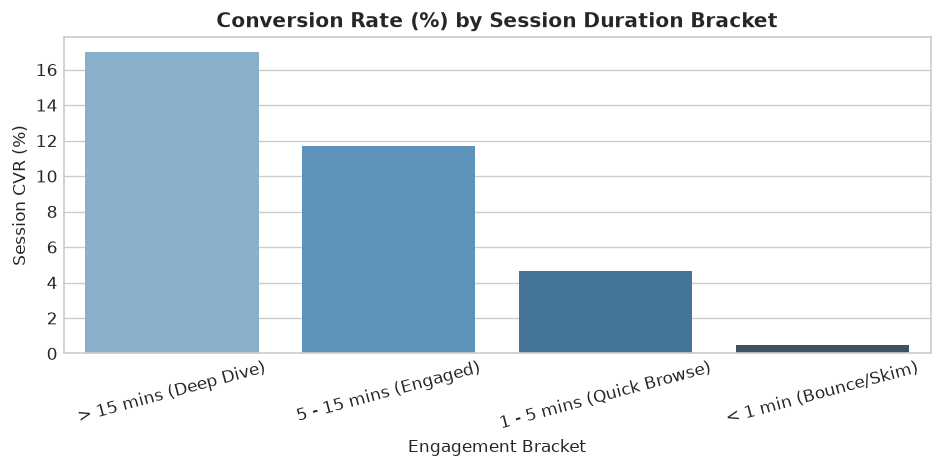

In [4]:
duration_matrix = con.execute("""
    SELECT 
        duration_bracket,
        SUM(step_purchase) AS purchased,
        COUNT(*) - SUM(step_purchase) AS not_purchased
    FROM session_segmented
    GROUP BY duration_bracket
    ORDER BY duration_bracket;
""").df()

contingency = duration_matrix[['purchased', 'not_purchased']].values
chi2, p_chi2, dof, _ = chi2_contingency(contingency)

print(f"Chi-Square: {chi2:.2f} | p-value: {p_chi2:.4e} | dof: {dof}")

# Plot Conversion Rate by Duration
dur_summary = con.execute("SELECT * FROM segment_duration_summary;").df()

plt.figure(figsize=(8, 4))
sns.barplot(data=dur_summary, x='duration_bracket', y='session_cvr_pct', palette='Blues_d')
plt.title("Conversion Rate (%) by Session Duration Bracket", fontweight='bold')
plt.ylabel("Session CVR (%)")
plt.xlabel("Engagement Bracket")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()